# 08 · Addresses Are Not Search Indexes

**NHyDB 0.27.1 notebook series · v1**

The address answers **where** a value lives. It does not answer **which** records contain a certain value – for that, NHyDB has secondary indexes. This notebook shows honestly what the address does, what an index adds, and how both work together.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* the difference between reading by address and searching by value
* the four index families VALUE, TOKEN, TRIGRAM and FULLTEXT (BM25)
* that indexes are real data structures: `build_indexes()`, freshness and `StaleIndexError`
* how the query planner chooses between index and scan (`explain`)
* how large the speed difference is – measured on your machine

**Recommended before:** [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import random
import statistics
import time

import pandas as pd
from nhydb.query import Q, QueryEngine


def timed(fn, repeat=5):
    """Median and spread of `repeat` runs of fn() in milliseconds, plus the last result."""
    times, result = [], None
    for _ in range(repeat):
        t0 = time.perf_counter()
        result = fn()
        times.append((time.perf_counter() - t0) * 1000)
    return statistics.median(times), min(times), max(times), result

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: two different questions

| question | example | answered by |
|---|---|---|
| **Where** is it? What is stored at record 4242, field 2? | `get_value(1, 4242, 2)` | the **address** – computed, no search |
| **Which** records have city = "Reykjavik"? | `find_u(1, {"by_city": "Reykjavik"})` | a **secondary index** – or a full scan |

The Dynadron address solves the identity problem: every cell has exactly one number, nothing has
to be looked up. But a *value* such as "Reykjavik" can appear in any record – no formula can know
where. That is the job of an index: a data structure that maps values to records.

> NHyDB's indexes are **not** maintained automatically. You build them with `build_indexes()`
> after writing. An index older than the data is *stale* – the engine detects that.

## 1 · A dataset of 50,000 people

▶ **Run it:** each person has a name, a city and an age. Every 1000th person lives in Reykjavik,
the rest are spread over eight other cities.

In [2]:
N_PEOPLE = 50_000                                   # ▶ Try it: dataset size
CITIES = ["Berlin", "Lisbon", "Kyoto", "Quito", "Oslo", "Lima", "Cairo", "Perth"]
random.seed(7)
people = [[f"person {i}", "Reykjavik" if i % 1000 == 0 else CITIES[i % 8], random.randint(18, 90)]
          for i in range(1, N_PEOPLE + 1)]

PATH = db_path("people.nhydb")
with nhydb.create(PATH) as db:
    db.create_realm(1, "people")
    db.create_shape(1, 1, "person", [{"v": 1, "name": "name", "type": "utf8"},
                                     {"v": 2, "name": "city", "type": "utf8"},
                                     {"v": 3, "name": "age", "type": "u8"}])
    db.create_classic_layout(1, 1, "people", shape_id=1)
    db.put_dense_batch(1, 1, people, shape_id=1)
print(f"{N_PEOPLE:,} records written; file size {os.path.getsize(PATH):,} bytes")
truth_reykjavik = [u for u, p in enumerate(people, start=1) if p[1] == "Reykjavik"]

50,000 records written; file size 1,198,200 bytes


## 2 · Address vs. scan vs. index

**Question:** How long does each of the three ways take?

1. **By address:** read the city of record 4242 – the cell is computed, no search.
2. **Scan:** find all Reykjavik records **without an index** – every record must be read.
3. **Index:** the same question with a VALUE index on `city`.

Each measurement is repeated five times; the bars show the median, the thin lines the range.

In [3]:
db = nhydb.open(PATH)
q = QueryEngine(db)

addr = timed(lambda: db.get_value(1, 4242, 2))
plan_scan = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
scan = timed(lambda: q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="n")["refs"])

db.create_index(1, 1, "by_city", "city")
build = db.build_indexes(commit=True)
plan_index = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
index = timed(lambda: q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="n")["refs"])

assert addr[3] == people[4241][1]
assert scan[3] == index[3] and len(index[3]) == len(truth_reykjavik)
print(f"plan without index: {plan_scan['access']:18} estimated rows {plan_scan['estimated_rows']:,}")
print(f"plan with index   : {plan_index['access']:18} estimated rows {plan_index['estimated_rows']:,}")
print(f"index build: {build['total_s'] * 1000:.1f} ms, index payload {build['indexes'][0]['payload_bytes']:,} bytes, "
      f"{build['indexes'][0]['distinct_values']} distinct cities")

plan without index: MATERIALIZED_SCAN  estimated rows 50,000
plan with index   : VALUE_INDEX        estimated rows 50
index build: 8.8 ms, index payload 53,239 bytes, 9 distinct cities


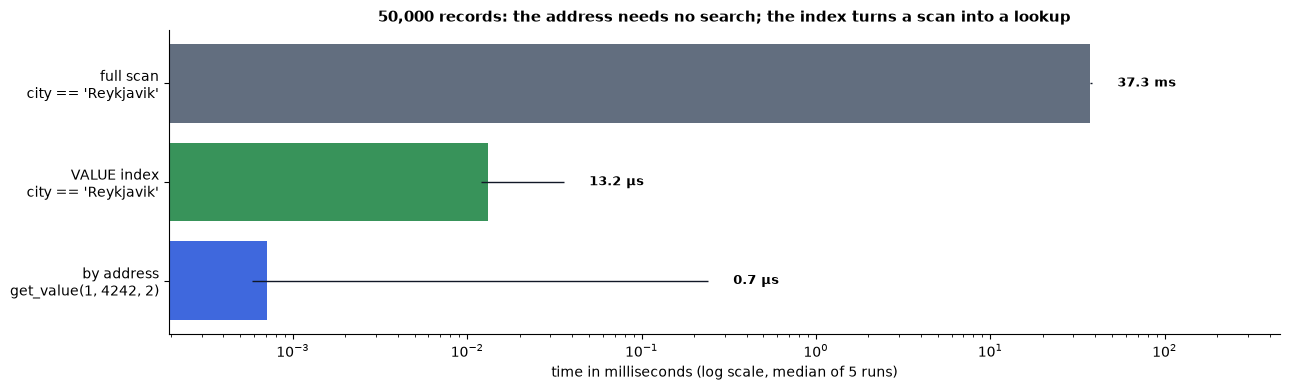

In [4]:
results = pd.DataFrame([
    {"way": "by address\nget_value(1, 4242, 2)", "median ms": addr[0], "min": addr[1], "max": addr[2], "layer": "A"},
    {"way": "VALUE index\ncity == 'Reykjavik'", "median ms": index[0], "min": index[1], "max": index[2], "layer": "B"},
    {"way": "full scan\ncity == 'Reykjavik'", "median ms": scan[0], "min": scan[1], "max": scan[2], "layer": "C"},
])
fig, ax = plt.subplots(figsize=(13, 4))
y = range(len(results))
ax.barh(y, results["median ms"], color=[COLORS[l] for l in results["layer"]], alpha=0.85)
ax.hlines(y, results["min"], results["max"], color="#111827", lw=1)
for yi, m, hi in zip(y, results["median ms"], results["max"]):
    label = f"{m * 1000:.1f} µs" if m < 0.1 else f"{m:.1f} ms"
    ax.text(max(m, hi) * 1.4, yi, label, va="center", fontsize=9, fontweight="bold")
ax.set_yticks(list(y))
ax.set_yticklabels(results["way"])
ax.set_xscale("log")
ax.set_xlabel("time in milliseconds (log scale, median of 5 runs)")
ax.set_title(f"{N_PEOPLE:,} records: the address needs no search; the index turns a scan into a lookup")
ax.set_xlim(results["min"].min() / 3, results["max"].max() * 12)
plt.tight_layout()
plt.show()

**What happened?**

* **Address:** microseconds – the engine computes where record 4242, field 2 lives and reads it.
  No search, no index, independent of the size of the database. (The long thin line is the very
  first read, which also loads the data block into memory.)
* **Scan:** every one of the 50,000 records is read and compared (`MATERIALIZED_SCAN`).
* **Index:** the planner switches to `VALUE_INDEX` and reads only the matching postings. The
  numbers depend on your machine – compare their ratio, not the absolute values.

**Ah – the address makes identity free; the index makes value search fast. They solve two
different problems.**

## 3 · Indexes go stale – and the engine notices

**Question:** What happens when data is written after the index was built?

▶ **Run it:** we add one more person from Reykjavik **without** rebuilding the index.

In [5]:
db.put(1, N_PEOPLE + 1, ["late arrival", "Reykjavik", 33], commit=True)

try:
    list(db.find_u(1, {"by_city": "Reykjavik"}))          # direct index API
except nhydb.StaleIndexError as e:
    print("find_u      →", type(e).__name__, ":", e)

stale_plan = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
count = q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="count")["count"]
print(f"QueryEngine → falls back to {stale_plan['access']}, count = {count} (correct, includes the new record)")
print("verify()    →", db.verify()["errors"])
assert count == len(truth_reykjavik) + 1 and stale_plan["access"] == "MATERIALIZED_SCAN"

db.build_indexes(commit=True)
fresh = list(db.find_u(1, {"by_city": "Reykjavik"}))
print(f"after build_indexes(): {len(fresh)} records via index, plan {q.explain(Q.field('city') == 'Reykjavik', realm=1)['plan']['access']}")
assert len(fresh) == len(truth_reykjavik) + 1 and db.verify()["ok"]

find_u      → StaleIndexError : Index 'by_city'/NL is missing or older than the data. Run build_indexes().
QueryEngine → falls back to MATERIALIZED_SCAN, count = 51 (correct, includes the new record)


verify()    → ['Index by_city/NL is stale']
after build_indexes(): 51 records via index, plan VALUE_INDEX


**What happened?** Three different safety reactions, all deliberate:

* The **direct index API** refuses to answer from an outdated index (`StaleIndexError`) – a
  wrong answer is never returned.
* The **QueryEngine** silently switches to a scan, so the answer is still correct, just slower.
* **`verify()`** lists the stale index as a problem until `build_indexes()` is called.

When to rebuild is the application's decision – for example after a batch import.

## 4 · Text indexes: TOKEN, TRIGRAM and FULLTEXT

**Question:** How do we search inside text?

| index | answers | example |
|---|---|---|
| **TOKEN** | contains whole words (case-insensitive) | `token("lane")` |
| **TRIGRAM** | contains a substring | `icontains("adro")` |
| **FULLTEXT** | words and phrases, ranked by relevance (BM25) | `fulltext("prime numbers")` |

A small library of articles that can be checked by eye:

In [6]:
ARTICLES = [
    ["The Dynadron", "the Dynadron arranges all natural numbers in groups around the squares"],
    ["Two lanes", "every cell has a left lane NL and a right lane NR with different numbers"],
    ["Boundary points", "squares and products of neighbours are boundary points, not cells"],
    ["Prime numbers", "prime numbers appear in both halves of every group of the Dynadron"],
    ["Realms", "a realm is a stretch of ten to the power of one hundred positions"],
    ["Indexes", "an index maps values to records; it must be rebuilt after writing"],
    ["Prime gaps", "gaps between prime numbers grow slowly; prime numbers never stop"],
    ["Layouts", "a layout decides how records and fields are placed on cells"],
]
TPATH = db_path("articles.nhydb")
with nhydb.create(TPATH) as tdb:
    tdb.create_realm(1, "kb")
    tdb.create_shape(1, 1, "article", [{"v": 1, "name": "title", "type": "utf8"},
                                       {"v": 2, "name": "body", "type": "utf8"}])
    tdb.create_classic_layout(1, 1, "articles", shape_id=1)
    tdb.put_dense_batch(1, 1, ARTICLES, shape_id=1)
    tdb.create_token_index(1, 1, "tok_body", "body")
    tdb.create_trigram_index(2, 1, "tri_title", "title", casefold=True)
    tdb.create_fulltext_index(3, 1, "ft_body", "body")
    tdb.build_indexes(commit=True)

    def titles(us):
        return [ARTICLES[u - 1][0] for u in us]

    print("TOKEN    'lane'          →", titles(tdb.index_candidates(1, "token", "lane")))
    print("TOKEN    all 'prime gaps' →", titles(tdb.index_candidates(1, "tokens_all", "prime gaps")))
    print("TRIGRAM  icontains 'ADRO' →", titles(tdb.index_candidates(2, "icontains", "ADRO")))
    print("FULLTEXT phrase 'boundary points' →", titles(tdb.index_candidates(3, "phrase", "boundary points")))
    assert titles(tdb.index_candidates(1, "token", "lane")) == ["Two lanes"]
    assert titles(tdb.index_candidates(2, "icontains", "ADRO")) == ["The Dynadron"]

    SEARCH = "prime numbers"                         # ▶ Try it: your own search words
    hits = QueryEngine(tdb).search(Q.fulltext("body", SEARCH), realm=1, select=["title"], limit=8)["rows"]
ranking = pd.DataFrame([{"title": h["title"], "BM25 relevance": round(h["relevance"], 3)} for h in hits])
ranking

TOKEN    'lane'          → ['Two lanes']
TOKEN    all 'prime gaps' → ['Prime gaps']
TRIGRAM  icontains 'ADRO' → ['The Dynadron']
FULLTEXT phrase 'boundary points' → ['Boundary points']


,title,BM25 relevance
0,Prime gaps,2.841
1,Prime numbers,1.966


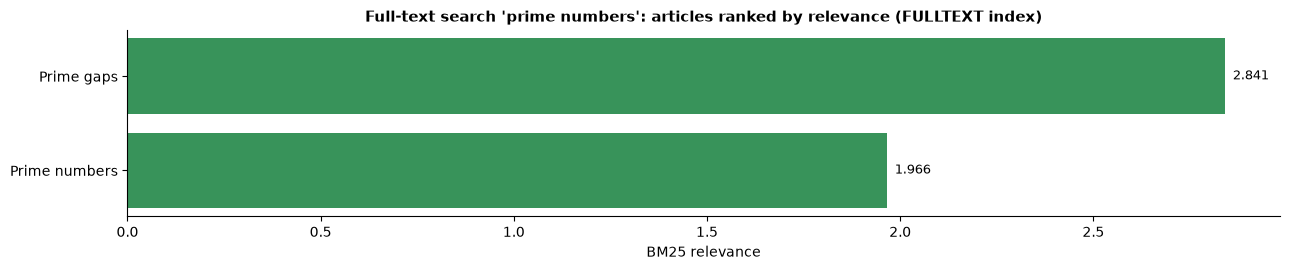

In [7]:
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.barh(ranking["title"][::-1], ranking["BM25 relevance"][::-1], color=COLORS["B"], alpha=0.85)
for i, v in enumerate(ranking["BM25 relevance"][::-1]):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("BM25 relevance")
ax.set_title(f"Full-text search '{SEARCH}': articles ranked by relevance (FULLTEXT index)")
plt.tight_layout()
plt.show()

**What happened?** "Prime gaps" mentions *prime numbers* twice and ranks first; "Prime numbers"
follows. Articles that mention neither word do not appear. BM25 is a standard ranking formula
from information retrieval: frequent words in short texts count more, words that occur in every
document count less.

## 5 · What the planner chooses

`explain` shows, for each kind of question, how the engine will answer it – before running it.
Structural questions about `u`, `v` or `N` are answered from the **address**, value questions
from an **index** if a fresh one exists, otherwise by a **scan**.

In [8]:
db.create_index(2, 1, "by_age", "age")
db.build_indexes(commit=True)
questions = {
    "city == 'Oslo'":          Q.field("city") == "Oslo",
    "age between 30 and 39":   Q.field("age").between(30, 39),
    "name == 'person 77'":     Q.field("name") == "person 77",
    "u between 100 and 200":   Q.u.between(100, 200),
    "city == 'Oslo' and age < 20": (Q.field("city") == "Oslo") & (Q.field("age") < 20),
}
rows = []
for text, expr in questions.items():
    plan = q.explain(expr, realm=1)["plan"]
    rows.append({"question": text, "access": plan.get("access", plan.get("node")),
                 "index": plan.get("index_name") or "–", "estimated rows": plan.get("estimated_rows")})
pd.DataFrame(rows).set_index("question")

,access,index,estimated rows
question,,,
city == 'Oslo',VALUE_INDEX,by_city,6250
age between 30 and 39,VALUE_INDEX,by_age,6746
name == 'person 77',MATERIALIZED_SCAN,–,50001
u between 100 and 200,STRUCT_RANGE,–,101
city == 'Oslo' and age < 20,AND,–,6250


`name` has no index, so the planner scans. For the combined question the plan is a tree (`AND`);
`db.explain_query(...)` / `q.explain(...)` return the full tree for inspection.

## Your turn

**Task:** how many people in Berlin are between 30 and 39 years old? Use the two indexes with
`db.find(...)`, then check the answer against plain Python on the original list.

In [9]:
found = list(db.find(1, {"by_city": "Berlin", "by_age": (30, 39)}))
truth = sum(1 for p in people if p[1] == "Berlin" and 30 <= p[2] <= 39)
print(f"index answer: {len(found)}   plain Python: {truth}")
assert len(found) == truth and all(r["city"] == "Berlin" and 30 <= r["age"] <= 39 for r in found)

index answer: 875   plain Python: 875


## ⏩ Advanced: estimates and costs

An index also answers *how many* without reading a single record, and its size is part of the
file. Indexes cost space and build time – which is why NHyDB lets you decide when to build them.
(The file is append-only: every `build_indexes()` writes new index blocks; the older ones stay
until a compaction – notebook 11.)

In [10]:
print("posting count 'Reykjavik':", db.posting_count(1, "Reykjavik"))
print("estimate age 30–39       :", db.index_candidate_estimate(2, "between", 30, 39))
stats = db.stats()["storage"]["by_block_type"]
print({k: v["bytes"] for k, v in stats.items()})
db.close()

posting count 'Reykjavik': 51
estimate age 30–39       : {'estimated_rows': 6746, 'exact': True, 'key_count': 1}
{'DATA_DENSE': 1189176, 'DB_CONFIG': 104, 'SECONDARY_INDEX': 257784, 'SYSTEM_R0_U1': 1464}


## Summary

* The address answers *where*: reading a known cell needs no search and no index.
* Searching by value needs an index (VALUE, TOKEN, TRIGRAM, FULLTEXT) – or a full scan.
* Indexes are built explicitly; stale indexes are detected: direct APIs refuse, the QueryEngine scans, `verify()` reports.
* `explain` shows whether an answer comes from the address, an index or a scan.

## Where to go next

* [09 · Asking Questions of the Data](09_queries_and_sql_v1.ipynb) – QueryEngine and NHySQL in depth.
* [13 · Measure, Don't Assume](13_benchmark_lab_v1.ipynb) – larger, repeatable measurements.

**Cookbook sections:** 13 (Secondary indexes), 14 (QueryEngine) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [11]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
